# FG risk · Які ділянки парку згорять наступними?

**Тип:** виміряно. **Навіщо:** Чи можна з рельєфу, лісистості й історії передбачити, які ділянки згорять, і чи переноситься прогноз з однієї пожежі на іншу.

Цей ноутбук повторює блок сторінки досліджень `web/science/#c` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('FG_risk'))

T3 · Просторовий ризик пожежі на сітці H3 (res 9 ≈ 0.1 км²).

Задача      ранжувати комірки парку за ймовірністю згоріти в наступний пожежний сезон → куди спрямувати патрулі, камери, профілактику.
Лейбли      y_burn_<Y>   — ≥ 20 % площі комірки в контурі події FIRMS (ST-DBSCAN) у році Y;
            y_hist       — втрата лісу Hansen 2001–2021 > 2 % комірки (20 років порушень: пожежі, рубки, вітровали);
            перевірка стійкості до визначення лейбла 2023: y_loss_2023_hansen (≥ 30 % лісу втрачено у 2023–24),
            y_dndvi_2023 (≥ 50 % пікселів з dNDVI MODIS > 0.275 — поріг чемпіона T1).
Ознаки      рельєф (SRTM), паливо (лісистість 2000), люди (OSM: дороги, села, треки, межа парку); динамічні — лише з даних ДО року Y.
Протокол    валідація (вибір підходу) — пожежа 2022: для підходів, що не бачили 2022;
                                         для навчених на 2022 — просторова GroupKFold(5) по блоках H3 res 6 всередині 2022;
            тест (звіт) — пожежа 2023, жоден підхід 

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_roc_auc,test_roc_auc,test_roc_auc_ci,test_roc_auc_hansen,test_roc_auc_dndvi,champion
0,f22_lgbm_all,0.706,0.525,0.450–0.605,0.424,0.362,True
1,f22_lgbm_static,0.680,0.529,0.459–0.599,0.418,0.365,False
2,f22_lr_all,0.645,0.451,0.373–0.518,0.420,0.336,False
3,hist_lgbm_terrain_fuel,0.613,0.855,0.824–0.884,0.910,0.846,False
4,hist_lgbm_terrain,0.608,0.862,0.829–0.891,0.925,0.854,False
5,hist_lgbm_static,0.606,0.841,0.806–0.870,0.874,0.815,False
6,hist_lr_static,0.597,0.847,0.811–0.882,0.948,0.866,False
7,treecover,0.592,0.875,0.843–0.901,0.959,0.884,False
8,elevation,0.585,0.887,0.853–0.916,0.971,0.913,False
9,hist_rf_static,0.585,0.825,0.788–0.856,0.859,0.802,False


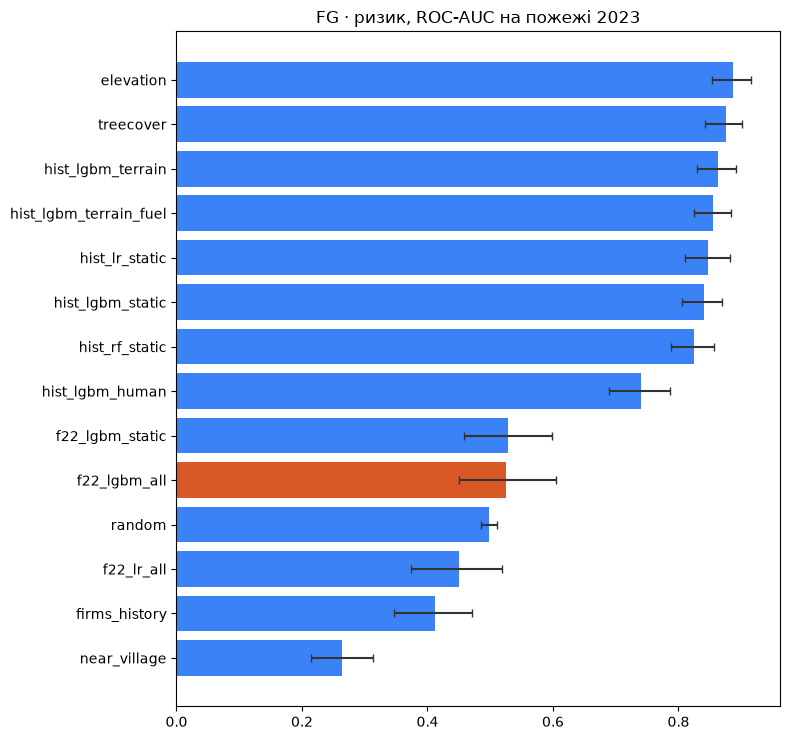

In [3]:
table, fig = report.show('FG_risk')
table